In [2]:
import numpy as np 
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d
from sklearn.preprocessing import StandardScaler
import pandas as pd
import pysindy as ps

import sys
sys.path.append('..')

from tools import SM90_deterministic, SM90_stochastic, ou_noise, plot_timeseries

from customSINDy import build_theta_SM90, customMIOSR, plot_cv_column, summary, print_model, all_subsets_R2, plot_rank_dR2

In [3]:
''' 
Insolaion
- Select last 1M years
- Create interp1d object
'''

berger90_insol = pd.read_csv('../forcing/palinsol_ber90_raw.csv')
R_df = berger90_insol.loc[berger90_insol['age_kyr'] <= 1000, ['age_kyr', 'Q65N_lam120_raw']].copy()
R_df['Q65N_lam120_std'] = (R_df['Q65N_lam120_raw'] - np.mean(R_df['Q65N_lam120_raw'])) / np.std(R_df['Q65N_lam120_raw'])
R = interp1d(
    R_df["age_kyr"][::-1] / 10, 
    R_df['Q65N_lam120_std'], 
    kind='linear',            
    bounds_error=False,        
    fill_value=0.0          
) 

Deterministic SM90 solution
- Deterministic SINDy fit

X (k=4): best = X + Y + Z + R   R2 = 0.9998
 rank       R2      dR2             terms
    1 0.999849 0.000000     X + Y + Z + R
    2 0.999143 0.000706 X + Y + R + X*X*Y
    3 0.999135 0.000714 X + Y + R + X*Y*Y
    4 0.999114 0.000735 X + Y + R + X*X*X
    5 0.999113 0.000735 X + Y + R + Y*Y*Z 

Y (k=5): best = Y + Z + Y*Z + Z*Z + Y*Z*Z   R2 = 0.9998
 rank       R2      dR2                       terms
    1 0.999799 0.000000   Y + Z + Y*Z + Z*Z + Y*Z*Z
    2 0.990738 0.009061   Y + Z + X*Y + Z*Z + Y*Z*Z
    3 0.981372 0.018426   Y + Z + X*Z + Y*Z + Y*Z*Z
    4 0.980663 0.019136 Y + Z + Z*Z + Y*Y*Z + Y*Z*Z
    5 0.978987 0.020811   Y + Z + X*Z + Y*Z + X*Y*Z 

Z (k=2): best = X + Z   R2 = 0.9998
 rank       R2      dR2     terms
    1 0.999845 0.000000     X + Z
    2 0.747305 0.252540     Y + R
    3 0.701265 0.298580     Y + Z
    4 0.684650 0.315195 R + Y*Y*Y
    5 0.675407 0.324438 Y + R*R*R 

X (4 terms) = -1.002 X + -1.000 Y + -0.201 Z + -0.600 R
0.9998486580716065
Y (5 terms) = 0

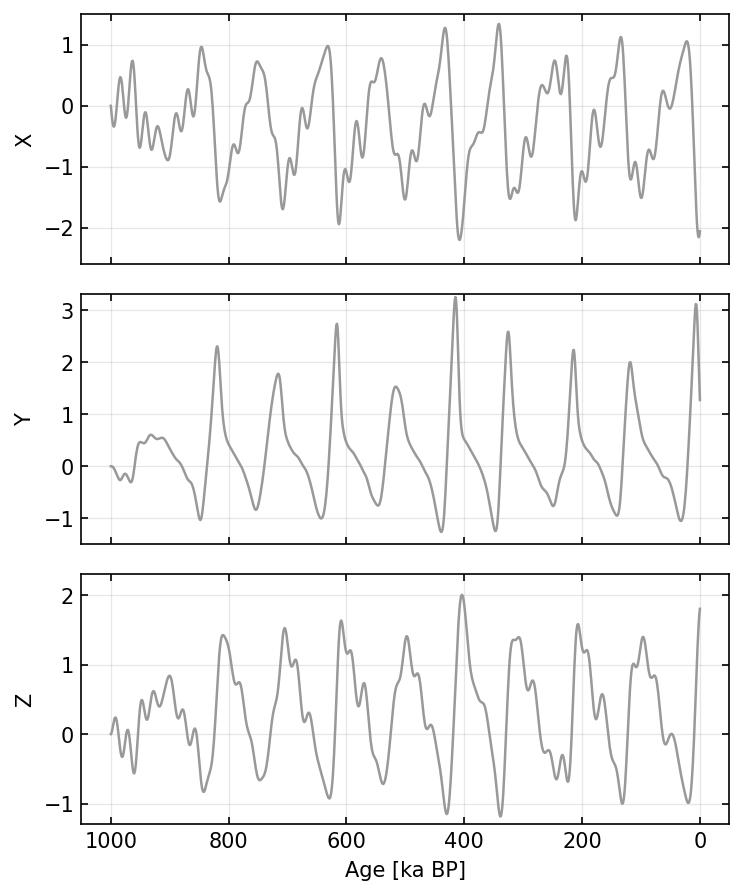

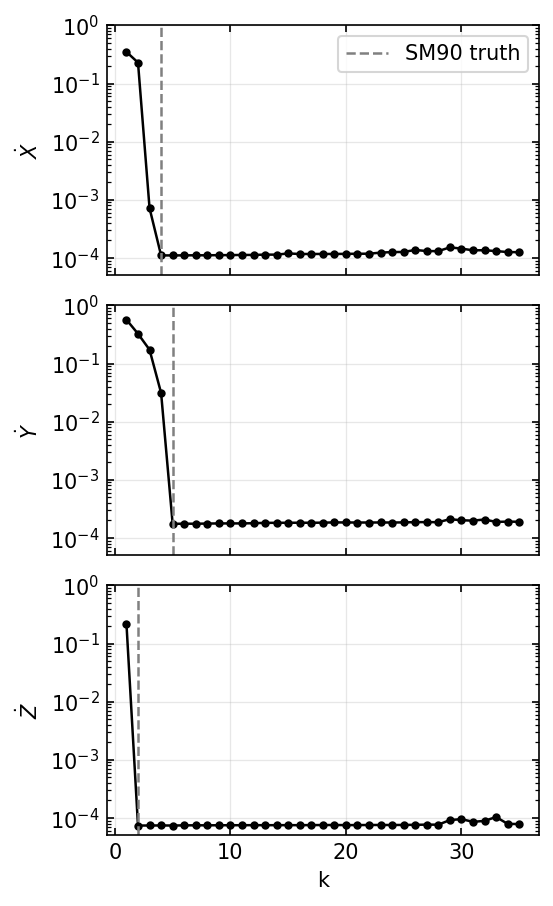

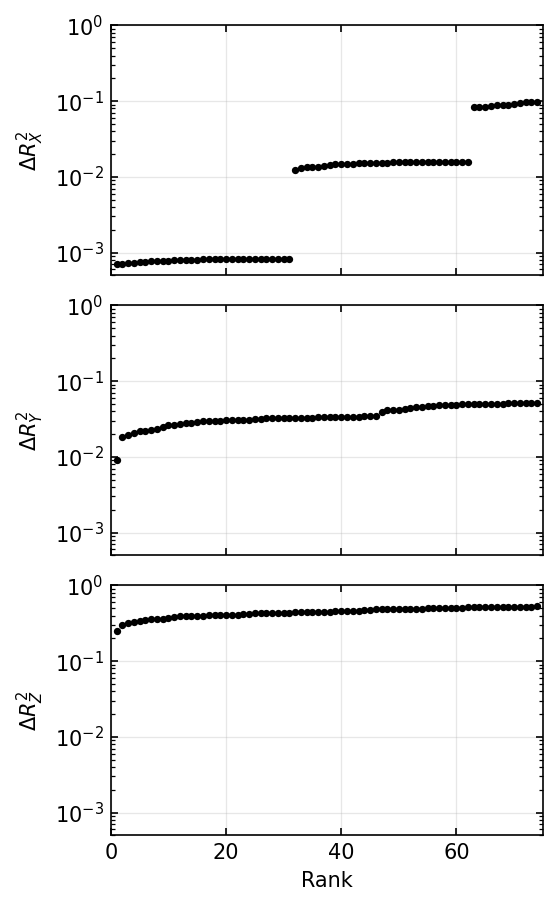

In [6]:
''' 
Deterministic SM90 solution
'''
dt = 0.1
t_end = 100
t = np.arange(0, t_end + dt/2, dt) # add 1/2 to cover sampling at 0-1 kyrs before present 
system_0 = np.array([0,0,0])
sol_deterministic = solve_ivp(SM90_deterministic, t_span=[0, t_end] , y0 = system_0, t_eval = t, args=(R,))

X_deterministic = sol_deterministic.y[0]
Y_deterministic = sol_deterministic.y[1]
Z_deterministic = sol_deterministic.y[2]

''' 
timeseries
'''
age_model = 1000 - 10 * sol_deterministic.t  
ys_deterministic = np.array([X_deterministic, Y_deterministic, Z_deterministic])
labels = ['X', 'Y', 'Z']
xlabel = 'Age [ka BP]'
width = 6
ylims = [(-2.6, 1.5), (-1.5, 3.3), (-1.3, 2.3)]
start=300
end=450 

plot_timeseries(age_model, 
                ys_deterministic, 
                ylim=ylims, 
                width=width, 
                labels=labels, 
                invert_xaxis=True,
                colors=['0.6'], true_color='black',   # grey: red noise, black: deterministic
                margins=True, save_path='figs_SM90/SM90_ts.pdf')

''' 
Deterministic CustomSSR SINDy fit
'''

spline_diff = ps.SINDyDerivative(kind="spline", s=1e-3)
dX_deterministic = spline_diff(X_deterministic.reshape(-1, 1), t)[:, 0]        
dY_deterministic = spline_diff(Y_deterministic.reshape(-1, 1), t)[:, 0]  
dZ_deterministic = spline_diff(Z_deterministic.reshape(-1, 1), t)[:, 0]  

R_deterministic = R(t)
Theta, _ = build_theta_SM90(X_deterministic, Y_deterministic, Z_deterministic, R_deterministic)

alpha = 0
sparsity_range = (1, 35)
Xmodels, XMMSEs, XR2s, Xdfs, optimal = customMIOSR(dX_deterministic, Theta, sparsity_range, n_blocks=6, normalize=True, alpha=alpha)
Ymodels, YMMSEs, YR2s, Ydfs, optimal = customMIOSR(dY_deterministic, Theta, sparsity_range, n_blocks=6, normalize=True, alpha=alpha)
Zmodels, ZMMSEs, ZR2s, Zdfs, optimal = customMIOSR(dZ_deterministic, Theta, sparsity_range, n_blocks=6, normalize=True, alpha=alpha)


''' 
CV column
'''
ylims_cv = [(10**-4.3, 1)] * 3
xlabel_cv = 'k'
ylabels_cv = [r"$\dot{X}$", r"$\dot{Y}$", r"$\dot{Z}$"]
sel_cv = [4, 5, 2]                      # SM90 truth: number of terms per equation

plot_cv_column([XMMSEs, YMMSEs, ZMMSEs],
               logy=True,
               ylabels=ylabels_cv,
               xlabel=xlabel_cv,
               ylim=ylims_cv,
               best=False,
               sel=sel_cv,
               selstring='SM90 truth',
               width=4,
               margins=True, save_path='figs_SM90/cv_deterministic.pdf')

''' 
uniqueness
'''
n_top = 75
dots_deterministic = {'X': dX_deterministic, 'Y': dY_deterministic, 'Z': dZ_deterministic}
Ks_deterministic = {'X': 4, 'Y': 5, 'Z':2}
subset_tables = {eq: all_subsets_R2(dots_deterministic[eq], Theta, k, n_top=n_top) for eq, k in Ks_deterministic.items()}

for eq, df in subset_tables.items():
    print(f"{eq} (k={Ks_deterministic[eq]}): best = {df['terms'].iloc[0]}   R2 = {df['R2'].iloc[0]:.4f}")
    print(df.head(5).to_string(index=False), '\n')

plot_rank_dR2(list(subset_tables.values()),
              y='dR2',
              ylabels=[r'$\Delta R^2_X$', r'$\Delta R^2_Y$', r'$\Delta R^2_Z$'],
              logy=True,
              width=4,
              margins=True, save_path='figs_SM90/deterministic_rank_dR2.pdf',
              ylim=(5e-4, 1),
              markers=True,
              ms= 2.5,
              drop_best=True)

''' 
Print models
'''
print_model(Xmodels, 4, 'X')
print(XR2s[4])
print_model(Ymodels, 5, 'Y')
print(YR2s[5])
print_model(Zmodels, 2, 'Z')
print(ZR2s[2])

Adding white noise
- Stochastic CustomSSR fit

X (k=3): best = X + Y + R   R2 = 0.9718
 rank       R2      dR2         terms
    1 0.971833 0.000000     X + Y + R
    2 0.966059 0.005774     Y + Z + R
    3 0.888851 0.082983 Y + Z + R*R*R
    4 0.861406 0.110427 X + Y + R*R*R
    5 0.848146 0.123687 Y + R + Z*Z*Z 

Y (k=5): best = Y + Z + Y*Z + Z*Z + Y*Z*Z   R2 = 0.9999
 rank       R2      dR2                       terms
    1 0.999882 0.000000   Y + Z + Y*Z + Z*Z + Y*Z*Z
    2 0.991992 0.007890   Y + Z + X*Y + Z*Z + Y*Z*Z
    3 0.980176 0.019706   Y + Z + Y*Z + Z*Z + X*Y*Z
    4 0.977320 0.022562 Y + Z + Z*Z + Y*Y*Z + Y*Z*Z
    5 0.974910 0.024972   X + Y + X*Z + Y*Z + Y*Z*Z 

Z (k=2): best = X + Z   R2 = 0.9997
 rank       R2      dR2     terms
    1 0.999732 0.000000     X + Z
    2 0.717624 0.282109     Y + R
    3 0.669314 0.330418 Y + Z*Z*R
    4 0.666789 0.332944     Y + Z
    5 0.661278 0.338455 Y + R*R*R 

X (3 terms) = -0.759 X + -0.945 Y + -0.565 R
0.9718332828368902
Y (5 terms) = 0.900 Y + -1.000 Z + -0.500 Y*Z + 0.999 

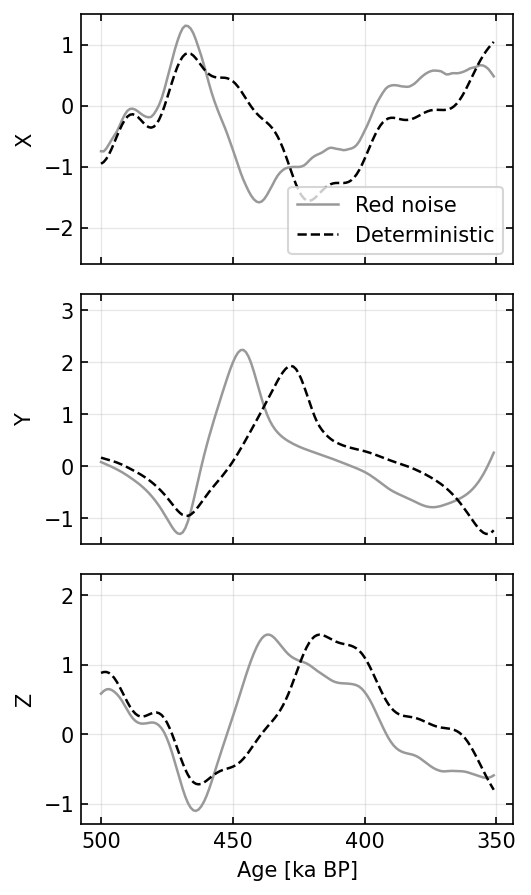

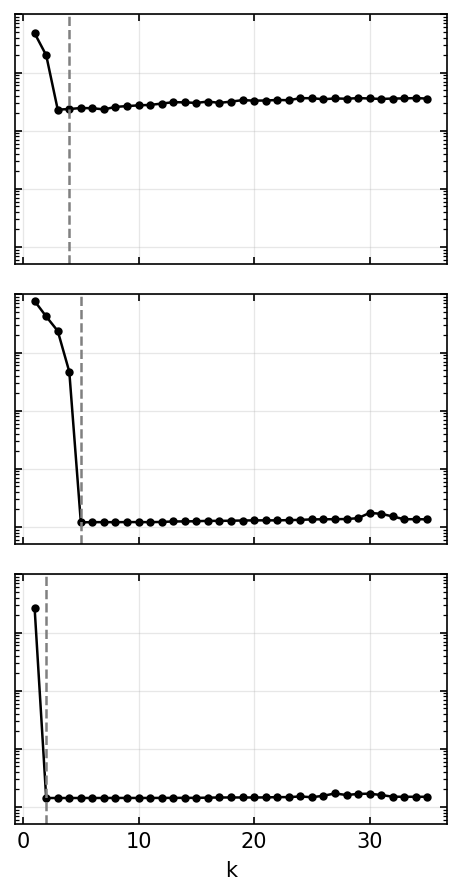

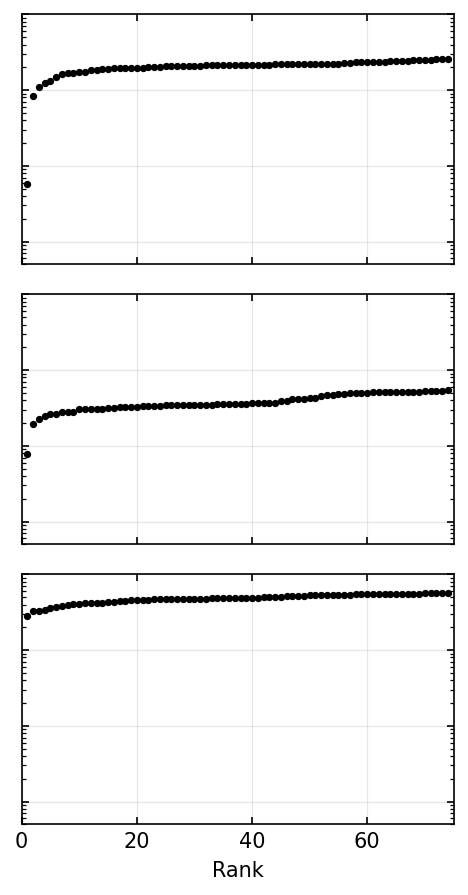

In [4]:
''' 
Add red noise to the solution
'''


''' 
OU red noise with:
- deterministic SM90 std
- 3 kyr AR
'''
rng = np.random.default_rng(42)
tau = 0.3
eta_ref = 0.185 #T06 paper noise fraction
sigma = eta_ref * np.std(np.gradient(sol_deterministic.y[0], dt))
noise = ou_noise(len(t_full), dt, tau, sigma, rng)
W = interp1d(
    t_full, 
    noise, 
    kind='linear',            
    bounds_error=False,        
    fill_value=0.0          
) 

''' 
Stochastic SM90
'''
n = 1

sol_stochastic = solve_ivp(SM90_stochastic, t_span=[0, t_end] , y0 = system_0, t_eval = t, args=(R, W, n))

X_stochastic = sol_stochastic.y[0]
Y_stochastic = sol_stochastic.y[1]
Z_stochastic = sol_stochastic.y[2]

''' 
Plot
'''
age_model = 1000 - 10 * sol_stochastic.t  
ys_deterministic = np.array([X_deterministic, Y_deterministic, Z_deterministic])
ys_stochastic = np.array([X_stochastic, Y_stochastic, Z_stochastic])
labels = ['X', 'Y', 'Z']
legends = ['Red noise', 'Deterministic']
xlabel = 'Age [ka BP]'
width = 4
ylims = [(-2.6, 1.5), (-1.5, 3.3), (-1.3, 2.3)]
start=300
end=450
window = (age_model[end - 1], age_model[start])   

plot_timeseries(age_model[start:end], 
                ys_stochastic[:,start:end], 
                ys_true=ys_deterministic[:,start:end], 
                ylim=ylims, 
                width=width, 
                labels=labels, 
                legends=legends, 
                invert_xaxis=True,
                colors=['0.6'], true_color='black',   # grey: red noise, black: deterministic
                margins=True, save_path='figs_red/ts_stochastic.pdf')


''' 
Stochastic CustomSSR SINDy fit
'''

spline_diff = ps.SINDyDerivative(kind="spline", s=1e-3)
dX_stochastic = spline_diff(X_stochastic.reshape(-1, 1), t)[:, 0]        
dY_stochastic = spline_diff(Y_stochastic.reshape(-1, 1), t)[:, 0]  
dZ_stochastic = spline_diff(Z_stochastic.reshape(-1, 1), t)[:, 0]  

R_stochastic = R(t)
Theta_stochastic, _ = build_theta_SM90(X_stochastic, Y_stochastic, Z_stochastic, R_stochastic)

alphas_stochastic = [0, 0, 0]
sparsity_range = (1, 35)
Xmodels, XMMSEs, XR2s, Xdfs, optimal = customMIOSR(dX_stochastic, Theta_stochastic, sparsity_range, n_blocks=6, normalize=True, alpha=alphas_stochastic[0])
Ymodels, YMMSEs, YR2s, Ydfs, optimal = customMIOSR(dY_stochastic, Theta_stochastic, sparsity_range, n_blocks=6, normalize=True, alpha=alphas_stochastic[1])
Zmodels, ZMMSEs, ZR2s, Zdfs, optimal = customMIOSR(dZ_stochastic, Theta_stochastic, sparsity_range, n_blocks=6, normalize=True, alpha=alphas_stochastic[2])

''' 
CV plot
'''

plot_cv_column([XMMSEs, YMMSEs, ZMMSEs],
               logy=True,
               xlabel=xlabel_cv,
               ylim=ylims_cv,
               best=False,
               sel=sel_cv,
               yticklabels=False,
               legend=False,
               width=width,
               margins=True, save_path='figs_red/cv_stochastic.pdf')

''' 
Uniqueness
'''

dots_stochastic = {'X': dX_stochastic, 'Y': dY_stochastic, 'Z': dZ_stochastic}
Ks_stochastic = {'X': 3, 'Y': 5, 'Z':2}
subset_tables = {eq: all_subsets_R2(dots_stochastic[eq], Theta_stochastic, k, n_top=n_top) for eq, k in Ks_stochastic.items()}

for eq, df in subset_tables.items():
    print(f"{eq} (k={Ks_stochastic[eq]}): best = {df['terms'].iloc[0]}   R2 = {df['R2'].iloc[0]:.4f}")
    print(df.head(5).to_string(index=False), '\n')

plot_rank_dR2(list(subset_tables.values()),
              y='dR2',
              ylabels=[r'$\Delta R^2_X$', r'$\Delta R^2_Y$', r'$\Delta R^2_Z$'],
              logy=True,
              width=4,
              margins=True, save_path='figs_red/stochastic_rank_dR2.pdf',
              ylim=(5e-4, 1),
              markers=True,
              ms= 2.5,
              drop_best=True,
              yticklabels=False)

''' 
Print models
'''
print_model(Xmodels, 3, 'X')
print(XR2s[3])
print_model(Ymodels, 5, 'Y')
print(YR2s[5])
print_model(Zmodels, 2, 'Z')
print(ZR2s[2])

Sample stochastic trajectory at proxy time steps

/var/folders/vx/_qz127vd3pz36ngtp3sys4fw0000gn/T/ipykernel_36665/1681898476.py:11: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  dO18_LR04 = pd.read_csv(f"{DATA_DIR}/Lisiecki_Raymo_2005/datasets/Global_stack_d18O.tab", comment="#", delim_whitespace=True)
/var/folders/vx/_qz127vd3pz36ngtp3sys4fw0000gn/T/ipykernel_36665/1681898476.py:15: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  co2_Yamamoto = pd.read_csv(f"{DATA_DIR}/CO2_YamamotoEtAl2022.csv", comment='#', delim_whitespace=True)
/var/folders/vx/_qz127vd3pz36ngtp3sys4fw0000gn/T/ipykernel_36665/1681898476.py:19: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  MgCa_elderfield = pd.read_csv(f"{DATA_DIR}/Elderfield_2012/datasets/181-1123_Mg_Ca.tab", c

(np.float64(351.0), np.float64(500.0))


(<Figure size 600x900 with 3 Axes>,
 array([<Axes: >, <Axes: >, <Axes: xlabel='Age [ka BP]'>], dtype=object))

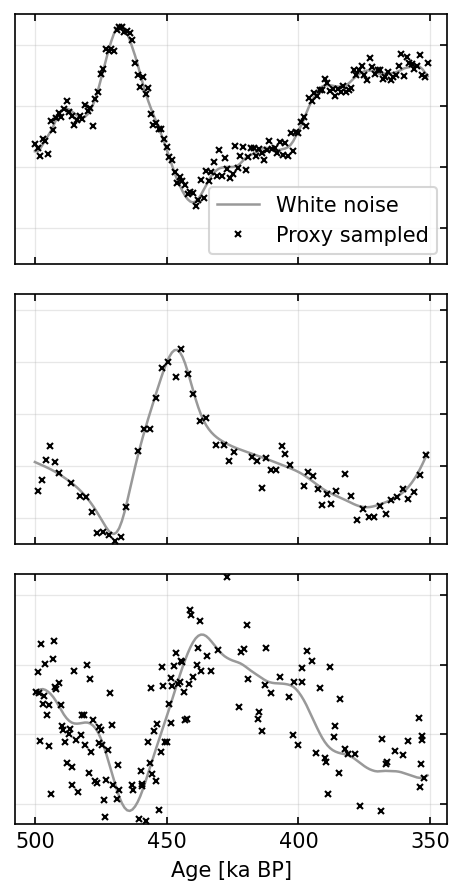

In [5]:
''' 
Sample stochastic trajectory at proxy time steps
'''

''' 
Read proxy records
'''

DATA_DIR = '../observations/Observations'

dO18_LR04 = pd.read_csv(f"{DATA_DIR}/Lisiecki_Raymo_2005/datasets/Global_stack_d18O.tab", comment="#", delim_whitespace=True)
dO18_LR04 = dO18_LR04.drop_duplicates(subset='Age[kaBP]').reset_index(drop=True)
age_dO18 = np.array(dO18_LR04.loc[dO18_LR04['Age[kaBP]'] <= 800, 'Age[kaBP]'].copy())

co2_Yamamoto = pd.read_csv(f"{DATA_DIR}/CO2_YamamotoEtAl2022.csv", comment='#', delim_whitespace=True)
co2_Yamamoto = co2_Yamamoto.drop_duplicates(subset='Age').reset_index(drop=True)
age_co2 = np.array(co2_Yamamoto.loc[co2_Yamamoto['Age'] <= 800, 'Age'].copy())

MgCa_elderfield = pd.read_csv(f"{DATA_DIR}/Elderfield_2012/datasets/181-1123_Mg_Ca.tab", comment="#", delim_whitespace=True)
MgCa_elderfield = MgCa_elderfield.drop_duplicates(subset='Age[kaBP]').reset_index(drop=True)
age_MgCa = np.array(MgCa_elderfield.loc[MgCa_elderfield['Age[kaBP]'] <= 800, 'Age[kaBP]'].copy())

''' 
Interpolate solutions and sample
'''

age_model = 1000 - 10 * sol_stochastic.t                 

X_interp = interp1d(
    age_model, 
    sol_stochastic.y[0], 
    kind='linear',            
    bounds_error=False,        
    fill_value=0.0          
)

Y_interp = interp1d(
    age_model, 
    sol_stochastic.y[1], 
    kind='linear',            
    bounds_error=False,        
    fill_value=0.0          
) 

Z_interp = interp1d(
    age_model, 
    sol_stochastic.y[2], 
    kind='linear',            
    bounds_error=False,        
    fill_value=0.0          
) 

X_sampled = X_interp(age_dO18)
Y_sampled = Y_interp(age_co2)
Z_sampled = Z_interp(age_MgCa)


''' 
Measurement noise
- X: pointwise LR04 dO18 uncertainty, standardised by the stack std
- Y, Z: white kernel noise level of a GP fitted to the CO2 and Mg/Ca records
- variances are computed before the noise is added, and reused by the GPR below
'''
from GPR import fitGPRtodata

var_X = np.array((dO18_LR04['d18O_StdDev_pm'].loc[dO18_LR04['Age[kaBP]'] <= 800] / np.std(dO18_LR04['d18O_stack[‰]'].loc[dO18_LR04['Age[kaBP]'] <= 800])) ** 2)
co2_regressed, co2_std, co2_gpr = fitGPRtodata(age_co2, np.array(co2_Yamamoto['Est_CO2_linear'].loc[co2_Yamamoto['Age'] <= 800]), age_co2, variance=None)
var_Y = co2_gpr.kernel_.k2.noise_level * np.var(Y_sampled)    
MgCa_regressed, MgCa_std, MgCa_gpr = fitGPRtodata(age_MgCa, np.array(MgCa_elderfield['Mg/Ca[mmol/mol](Normalized)'].loc[MgCa_elderfield['Age[kaBP]'] <= 800]), age_MgCa, variance=None)
var_Z = MgCa_gpr.kernel_.k2.noise_level * np.var(Z_sampled)   

rng_obs = np.random.default_rng(0)
X_sampled = X_sampled + np.sqrt(var_X) * rng_obs.standard_normal(len(X_sampled))
Y_sampled = Y_sampled + np.sqrt(var_Y) * rng_obs.standard_normal(len(Y_sampled))
Z_sampled = Z_sampled + np.sqrt(var_Z) * rng_obs.standard_normal(len(Z_sampled))


''' 
Plot
'''
ys_sampled = [X_sampled, Y_sampled, Z_sampled]
xs_sampled = [age_dO18, age_co2, age_MgCa]

print(window)
masks = [(age >= window[0]) & (age <= window[1]) for age in xs_sampled]

xs_cut = [age[m] for age, m in zip(xs_sampled, masks)]
ys_cut = [y[m]   for y,   m in zip(ys_sampled, masks)]

legends = ['White noise', 'Proxy sampled']

plot_timeseries(age_model[start:end], 
                ys_stochastic[:, start:end], 
                ys_true=ys_cut, 
                x_true=xs_cut,
                ylim = ylims,
                yticks=False, 
                width=width, 
                xlabel=xlabel, 
                legends=legends, 
                true_as_points=True, 
                invert_xaxis=True,
                colors=['0.6'], true_color='black',   # black crosses: proxy samples, as in gp_fit
                margins=True, save_path='figs_red/ts_proxy_sampled.pdf')

GPR 
- Sanity check
- CustomSSR fit to the GP mean

X (k=3): best = X + Y + R   R2 = 0.9371
 rank       R2      dR2         terms
    1 0.937052 0.000000     X + Y + R
    2 0.918957 0.018095     Y + Z + R
    3 0.833641 0.103411 Y + Z + R*R*R
    4 0.825912 0.111140 X + Y + R*R*R
    5 0.819342 0.117710 Y + R + X*Z*Z 

Y (k=4): best = Y + Z + Z*Z + X*Y*Z   R2 = 0.8197
 rank       R2      dR2               terms
    1 0.819748 0.000000 Y + Z + Z*Z + X*Y*Z
    2 0.807260 0.012488 Y + Z + Z*Z + X*X*Y
    3 0.801704 0.018044 X + Y + Z*Z + X*Y*Z
    4 0.801702 0.018046 X + Y + X*Z + X*Y*Z
    5 0.798871 0.020877 Y + Z + X*Z + X*Y*Z 

Z (k=3): best = Y + Z + R   R2 = 0.7739
 rank       R2      dR2         terms
    1 0.773911 0.000000     Y + Z + R
    2 0.750656 0.023255     X + Y + Z
    3 0.734866 0.039045 Y + Z + R*R*R
    4 0.733542 0.040369     X + Y + R
    5 0.729946 0.043965 Y + Z + X*Z*R 

X (3 terms) = -0.748 X + -0.951 Y + -0.545 R
0.9370520291369998
Y (4 terms) = 0.740 Y + -1.024 Z + 0.595 Z*Z + 0.630 X*Y*Z
0.8197477939870175
Z 

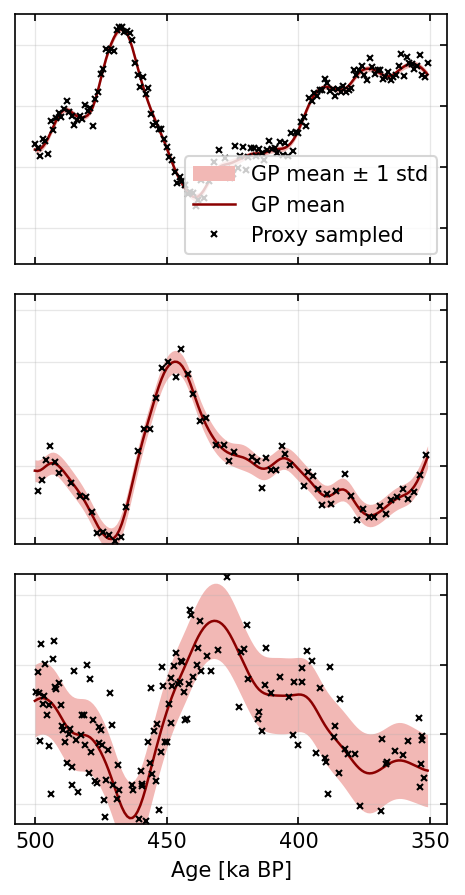

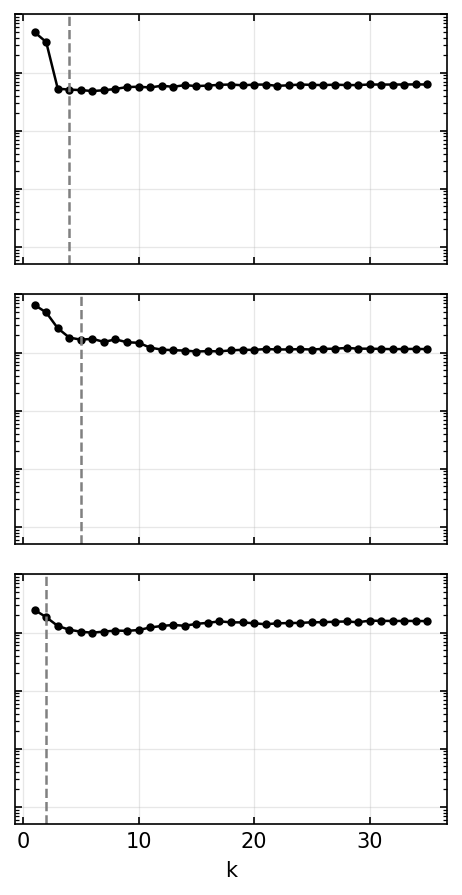

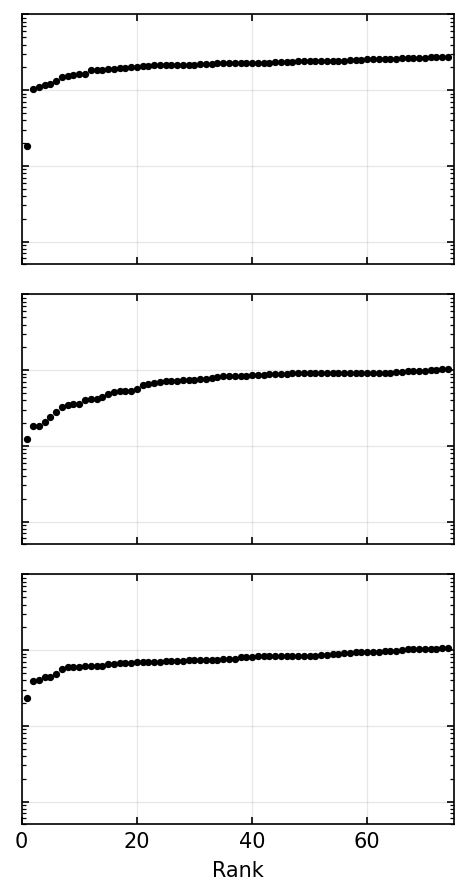

In [6]:
'''  
GPR
'''

from GPR import fitGPRtodata, gpr_derivative, sanity, gp_joint_posterior, draw_joint_samples, plot_gp_spaghetti
tgrid = age_model[-800:]

''' 
GPR to sampled trajectories
- fitted as the proxy records: X noise prescribed (dO18 uncertainty), Y and Z noise estimated by the white kernel
- GPR derivatives are on 1kyr timescales and follow reverse time axis, rescale with * -10
'''

X_regressed, X_std, X_gpr = fitGPRtodata(age_dO18, X_sampled, tgrid, variance = var_X)
X_dot = gpr_derivative(X_gpr, tgrid, X_sampled) * -10

Y_regressed, Y_std, Y_gpr = fitGPRtodata(age_co2, Y_sampled, tgrid, variance=None) 
Y_dot = gpr_derivative(Y_gpr, tgrid, Y_sampled) * -10

Z_regressed, Z_std, Z_gpr = fitGPRtodata(age_MgCa, Z_sampled, tgrid, variance=None) 
Z_dot = gpr_derivative(Z_gpr, tgrid, Z_sampled) * -10

''' 
Plot
'''
series = {
    'X':      (age_dO18,    X_sampled,    X_regressed,    X_std),
    'Y':   (age_co2,    Y_sampled,    Y_regressed,    Y_std),
    'Z': (age_MgCa,    Z_sampled,    Z_regressed,    Z_std),
}
sanity(series, window, tgrid, ylim=ylims, yticks=False, width=width, margins=True, save_path='figs_red/gp_fit.pdf')


''' 
GP mean CustomMIOSR SINDy fit
'''

R_GPR = R((1000 - tgrid) / 10)       
Theta_regressed, _ = build_theta_SM90(X_regressed, Y_regressed, Z_regressed, R_GPR)

alphas_gpr = [0, 0, 0]
sparsity_range = (1, 35)
Xmodels, XMMSEs, XR2s, Xdfs, optimal = customMIOSR(X_dot, Theta_regressed, sparsity_range, n_blocks=6, normalize=True, alpha=alphas_gpr[0])
Ymodels, YMMSEs, YR2s, Ydfs, optimal = customMIOSR(Y_dot, Theta_regressed, sparsity_range, n_blocks=6, normalize=True, alpha=alphas_gpr[1])
Zmodels, ZMMSEs, ZR2s, Zdfs, optimal = customMIOSR(Z_dot, Theta_regressed, sparsity_range, n_blocks=6, normalize=True, alpha=alphas_gpr[2])


''' 
CV plot
'''
plot_cv_column([XMMSEs, YMMSEs, ZMMSEs],
               logy=True,
               xlabel=xlabel_cv,
               ylim=ylims_cv,
               best=False,
               sel=sel_cv,
               yticklabels=False,
               legend=False,
               width=width,
               margins=True, save_path='figs_red/cv_gp_mean.pdf')


''' 
Uniqueness
'''

dots_gp = {'X': X_dot, 'Y': Y_dot, 'Z': Z_dot}
Ks_gp = {'X': 3, 'Y': 4, 'Z':3}
subset_tables = {eq: all_subsets_R2(dots_gp[eq], Theta_regressed, k, n_top=n_top) for eq, k in Ks_gp.items()}


for eq, df in subset_tables.items():
    print(f"{eq} (k={Ks_gp[eq]}): best = {df['terms'].iloc[0]}   R2 = {df['R2'].iloc[0]:.4f}")
    print(df.head(5).to_string(index=False), '\n')

plot_rank_dR2(list(subset_tables.values()),
              y='dR2',
              ylabels=[r'$\Delta R^2_X$', r'$\Delta R^2_Y$', r'$\Delta R^2_Z$'],
              logy=True,
              width=4,
              margins=True, save_path='figs_red/gp_rank_dR2.pdf',
              ylim=(5e-4, 1),
              markers=True,
              ms= 2.5,
              drop_best=True,
              yticklabels=False)

''' 
Print equations
'''

print_model(Xmodels, 3, 'X')
print(XR2s[3])
print_model(Ymodels, 4, 'Y')
print(YR2s[4])
print_model(Zmodels, 3, 'Z')
print(ZR2s[3])

GPR MC draws
- Double check diagnostics and CO2 and MgCa variances

X  (length scale 13.1 kyr)
  1. mean vs gpr.predict         max|diff| = 3.57e-14
  2. gpr_derivative = c * dmean  c = -10.000   rel. residual = 3.2e-14
  3. sample std / predict std    median    = 0.994   (1 points with zero predict std)
  4. gradient(x) vs xdot         rel. RMS  = 0.037
  5. noise SD (RMS)  GP = 0.124 (prescribed 0.124, white 0)   added = 0.124   GP/added = 1.00
  6. truth / draw spread         x = 0.89   xdot = 0.70   95% coverage = 0.96
Y  (length scale 12.7 kyr)
  1. mean vs gpr.predict         max|diff| = 1.39e-14
  2. gpr_derivative = c * dmean  c = -10.000   rel. residual = 1.5e-14
  3. sample std / predict std    median    = 0.487   (0 points with zero predict std)
  4. gradient(x) vs xdot         rel. RMS  = 0.038
  5. noise SD (RMS)  GP = 0.188 (prescribed 8.67e-06, white 0.188)   added = 0.201   GP/added = 0.94
  6. truth / draw spread         x = 1.11   xdot = 0.90   95% coverage = 0.89
Z  (length scale 14.0 kyr)
  1. mean vs gpr.predict         max|diff| =

(<Figure size 600x900 with 3 Axes>,
 array([[<Axes: >],
        [<Axes: >],
        [<Axes: xlabel='Age [ka BP]'>]], dtype=object))

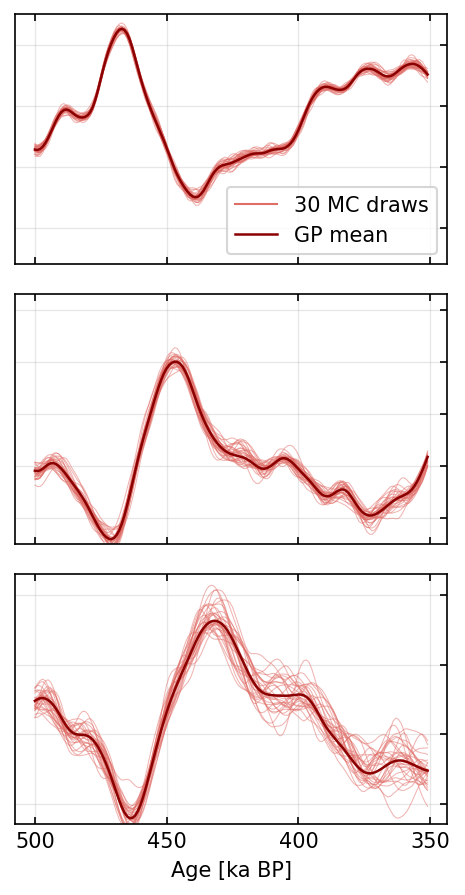

In [7]:
''' 
GPR MC draws
'''

rng = np.random.default_rng(42)
n_draws = 200
N = len(tgrid)

records = {
    "X":    (X_gpr,    age_dO18,    X_sampled,    X_regressed,    X_std,    X_dot),
    "Y":    (Y_gpr,    age_co2,    Y_sampled,    Y_regressed,    Y_std,    Y_dot),
    "Z":    (Z_gpr,    age_MgCa,    Z_sampled,    Z_regressed,    Z_std,    Z_dot),
}

samples = {}
added_noise_var = {'X': var_X, 'Y': var_Y, 'Z': var_Z}          # variances, as computed before adding noise
truth = {'X': X_stochastic[-800:], 'Y': Y_stochastic[-800:], 'Z': Z_stochastic[-800:]}


def gp_noise_sd(gpr, y):
    """RMS observation-noise SDs in original units: (prescribed alpha, white kernel, total).
    Assumes alpha and the white noise level are in normalised units, as with normalize_y=True."""
    y = np.asarray(y, float).ravel()
    y_sd = y.std()
    kern = gpr.kernel_
    white = kern.k2.noise_level if hasattr(kern, "k2") else 0.0
    alpha = np.mean(np.broadcast_to(gpr.alpha, y.shape))
    return y_sd * np.sqrt(alpha), y_sd * np.sqrt(white), y_sd * np.sqrt(alpha + white)


def gp_calibration(x_s, xdot_s, mu, x_true, xdot_true):
    N = x_s.shape[1]
    m, md = mu[:N], mu[N:]
    ratio_x    = np.sqrt(np.mean((x_true - m) ** 2) / np.mean((x_s - m) ** 2))
    ratio_xdot = np.sqrt(np.mean((xdot_true - md) ** 2) / np.mean((xdot_s - md) ** 2))
    lo, hi = np.percentile(x_s, [2.5, 97.5], axis=0)
    return ratio_x, ratio_xdot, np.mean((x_true >= lo) & (x_true <= hi))


samples = {}
for name, (gpr, X, y, mean_ref, std_ref, dot_ref) in records.items():
    mu, cov, ell = gp_joint_posterior(gpr, X, y, tgrid)
    x_s, xdot_s = draw_joint_samples(mu, cov, n_draws, rng)
    samples[name] = {"x": x_s, "xdot": xdot_s}

    mean_ref, std_ref, dot_ref = map(np.ravel, (mean_ref, std_ref, dot_ref))
    fd = np.gradient(x_s, tgrid, axis=1)
    d = mu[N:]
    print(f"{name}  (length scale {ell:.1f} kyr)")
    print(f"  1. mean vs gpr.predict         max|diff| = {np.max(np.abs(mu[:N] - mean_ref)):.2e}")

    c = (dot_ref @ d) / (d @ d)                       # best factor with dot_ref = c * dmean
    res = np.sqrt(np.mean((dot_ref - c * d) ** 2) / np.mean(dot_ref ** 2))
    print(f"  2. gpr_derivative = c * dmean  c = {c:.3f}   rel. residual = {res:.1e}")

    ok = std_ref > 0
    print(f"  3. sample std / predict std    median    = {np.median(x_s.std(0)[ok] / std_ref[ok]):.3f}"
          f"   ({(~ok).sum()} points with zero predict std)")
    print(f"  4. gradient(x) vs xdot         rel. RMS  = "
          f"{np.sqrt(np.mean((fd - xdot_s) ** 2) / np.mean(xdot_s ** 2)):.3f}")

    sd_added = float(np.sqrt(np.mean(added_noise_var[name])))    # RMS of the added SDs
    sd_alpha, sd_white, sd_gp = gp_noise_sd(gpr, y)
    print(f"  5. noise SD (RMS)  GP = {sd_gp:.3g} (prescribed {sd_alpha:.3g}, white {sd_white:.3g})"
          f"   added = {sd_added:.3g}   GP/added = {sd_gp / sd_added:.2f}")

    x_true = np.ravel(truth[name])
    assert x_true.shape == tgrid.shape, f"{name}: truth has {x_true.size} points, tgrid {tgrid.size}"
    xdot_true = np.gradient(x_true, tgrid)            # same units as dmean (per kyr of age)
    rx, rxd, cov95 = gp_calibration(x_s, xdot_s, mu, x_true, xdot_true)
    print(f"  6. truth / draw spread         x = {rx:.2f}   xdot = {rxd:.2f}   95% coverage = {cov95:.2f}")


means = {"X": X_regressed, "Y": Y_regressed, "Z": Z_regressed}
plot_gp_spaghetti(samples, tgrid, means=means, n_show=30, window=window, width=width,
                  ylim=ylims, yticks=False, margins=True, save_path='figs_red/gp_spaghetti.pdf')


MC CustomSSR SINDy

In [8]:
''' 
MC CustomMIOSR SINDy
'''

import pysindy as ps
from gurobipy import GRB


R_GPR = R((1000 - tgrid) / 10) 
X = samples['X']['x'].T
dX = samples['X']['xdot'].T
Y = samples['Y']['x'].T
dY = samples['Y']['xdot'].T
Z = samples['Z']['x'].T
dZ = samples['Z']['xdot'].T

Ks = {'X': 3, 'Y': 4, 'Z': 3}
models_mean = {'X': Xmodels, 'Y': Ymodels, 'Z': Zmodels}
ref_support = {eq: list(models_mean[eq][k].index) for eq, k in Ks.items()}
models  = {model: {} for model in Ks}   
fixed   = {model: {} for model in Ks}   
optimal = {model: {} for model in Ks}

normalize = True
timeout = 30
alphas_MC = {'X': 0, 'Y': 0, 'Z': 0}
for i in np.arange(X.shape[1]):

    print(f"draw {i}")

    States = {'X': X[:,i], 'Y': Y[:,i], 'Z': Z[:,i]}
    dots = {'X': dX[:,i] * -10, 'Y': dY[:,i] * -10, 'Z': dZ[:,i] * -10}
    
    Theta, _ = build_theta_SM90(States['X'], States['Y'], States['Z'], R_GPR)
    A = Theta.to_numpy()
    scale = np.linalg.norm(A, axis=0) if normalize else np.ones(A.shape[1])

    for model, k in Ks.items():

        y = dots[model]
        opt = ps.MIOSR(target_sparsity=k, alpha=alphas_MC[model], regression_timeout=timeout)
        opt.fit(A / scale, y)
        w = pd.Series(opt.coef_[0] / scale, index=Theta.columns)
        optimal[model][i] = opt.model.Status == GRB.OPTIMAL
        models[model][i] = w

        S   = ref_support[model]
        idx = Theta.columns.get_indexer(S)
        B   = A[:, idx] / scale[idx]                     
        c   = np.linalg.solve(B.T @ B + alphas_MC[model] * np.eye(len(S)), B.T @ y)
        fixed[model][i] = pd.Series(c / scale[idx], index=S)

draw 0
draw 1
draw 2
draw 3
draw 4
draw 5
draw 6
draw 7
draw 8
draw 9
draw 10
draw 11
draw 12
draw 13
draw 14
draw 15
draw 16
draw 17
draw 18
draw 19
draw 20
draw 21
draw 22
draw 23
draw 24
draw 25
draw 26
draw 27
draw 28
draw 29
draw 30
draw 31
draw 32
draw 33
draw 34
draw 35
draw 36
draw 37
draw 38
draw 39
draw 40
draw 41
draw 42
draw 43
draw 44
draw 45
draw 46
draw 47
draw 48
draw 49
draw 50
draw 51
draw 52
draw 53
draw 54
draw 55
draw 56
draw 57
draw 58
draw 59
draw 60
draw 61
draw 62
draw 63
draw 64
draw 65
draw 66
draw 67
draw 68
draw 69
draw 70
draw 71
draw 72
draw 73
draw 74
draw 75
draw 76
draw 77
draw 78
draw 79
draw 80
draw 81
draw 82
draw 83
draw 84
draw 85
draw 86
draw 87
draw 88
draw 89
draw 90
draw 91
draw 92
draw 93
draw 94
draw 95
draw 96
draw 97
draw 98
draw 99
draw 100
draw 101
draw 102
draw 103
draw 104
draw 105
draw 106
draw 107
draw 108
draw 109
draw 110
draw 111
draw 112
draw 113
draw 114
draw 115
draw 116
draw 117
draw 118
draw 119
draw 120
draw 121
draw 122
dra

In [9]:
models_mean_k = {'X': Xmodels[3], 'Y': Ymodels[4], 'Z': Zmodels[3]}
MIORS_dfs = {model: pd.DataFrame(dict).T for model, dict in models.items()}
fixed_dfs = {model: pd.DataFrame(dict).T for model, dict in fixed.items()}
summaries = {}
for model, df in MIORS_dfs.items():

    df['optimal'] = pd.Series(optimal[model])
    print(f"model={model}: {(~df["optimal"]).sum()} fit(s) not proven optimal")
    summaries[model] = summary(fixed_dfs[model], MIORS_dfs[model], models_mean_k[model])





model=X: 0 fit(s) not proven optimal
model=Y: 0 fit(s) not proven optimal
model=Z: 0 fit(s) not proven optimal


In [10]:
summaries['X']

,GP,mu,med,lo,hi,inc,occurrence
X,-0.747518,-0.727315,-0.727546,-0.768930,-0.690080,0.995,0.995
Y,-0.950761,-0.926567,-0.927164,-0.963404,-0.890663,1.000,0.995
R,-0.545256,-0.544488,-0.545188,-0.574029,-0.515689,1.000,0.995


In [11]:
summaries['Y']

,GP,mu,med,lo,hi,inc,occurrence
Y,0.740465,0.699701,0.701411,0.619712,0.785041,1.000,0.205
Z,-1.023720,-0.933419,-0.937785,-1.046331,-0.813308,0.400,0.205
Z*Z,0.594796,0.513117,0.511198,0.418552,0.610582,0.575,0.205
X*Y*Z,0.630304,0.593006,0.590544,0.522372,0.670134,0.685,0.205


In [12]:
summaries['Z']

,GP,mu,med,lo,hi,inc,occurrence
Y,0.631715,0.615540,0.615545,0.571528,0.658055,1.000,0.915
Z,-0.321581,-0.299871,-0.300794,-0.349205,-0.239814,1.000,0.915
R,0.257841,0.260027,0.261389,0.176772,0.335682,0.915,0.915
